# 04 · Aprendizaje no supervisado — tipos de pozo
Cada pozo se representa por la **forma de su curva** en los primeros 12 meses (producción / pico), el tamaño del pico de petróleo y gas, y el GOR. Comprimimos con **SVD** y agrupamos con **K-Means**; comparamos con **DBSCAN**.

**Contenido:** 1) representación y SVD · 2) elección de k (codo, silhouette, Davies-Bouldin, Calinski-Harabasz) · 3) DBSCAN · 4) perfiles y gráficos de los clusters · 5) validación (silhouette por pozo, tabla de contingencia) · conclusiones.

> **Qué hace esta celda:** importa las librerías, carga la configuración del proyecto (rutas y umbrales de `src/ypf_ds/config.py`) y define el estilo de los gráficos.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

> **Qué hace esta celda:** arma la matriz de pozos (forma de curva normalizada + picos + GOR) con la misma función que usa el entrenamiento y la estandariza.

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from ypf_ds.models.cluster import matriz_pozos, describir, MESES
import joblib
panel, pozos = pl.read_parquet(config.PANEL), pl.read_parquet(config.POZOS)
ids, M = matriz_pozos(panel, pozos)
Ms = StandardScaler().fit_transform(M)
print("Pozos:", len(ids), "| dimensiones:", M.shape[1])

Pozos: 4144 | dimensiones: 15


## 1. SVD: ¿cuántas componentes?

> **Qué hace esta celda:** aplica SVD con 12 componentes y grafica la varianza explicada individual y acumulada para elegir cuántas conservar.

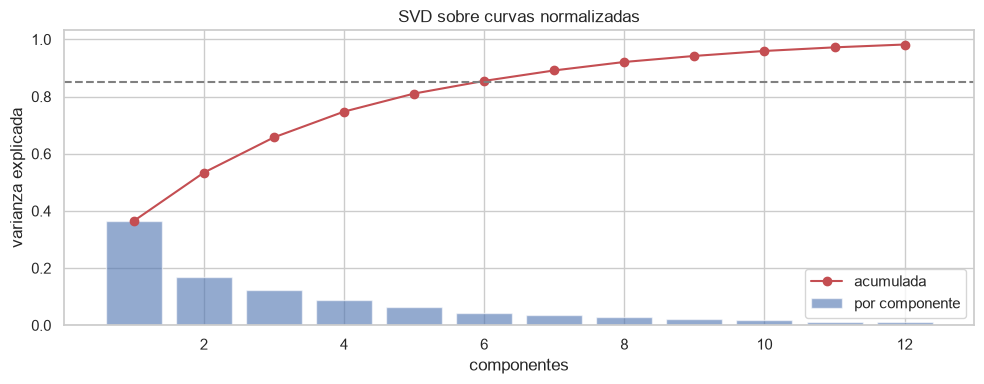

Varianza con 6 componentes: 0.855


In [3]:
svd = TruncatedSVD(n_components=12, random_state=42).fit(Ms)
var = np.cumsum(svd.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, 13), svd.explained_variance_ratio_, alpha=.6, label="por componente")
ax.plot(range(1, 13), var, marker="o", color="C3", label="acumulada"); ax.axhline(.85, ls="--", c="gray")
ax.set_xlabel("componentes"); ax.set_ylabel("varianza explicada"); ax.set_title("SVD sobre curvas normalizadas"); ax.legend()
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_svd.png", dpi=110); plt.show()
print("Varianza con 6 componentes:", round(var[5], 3))

> **Qué hace esta celda:** muestra qué variables pesan en las dos primeras componentes (cargas de la SVD), para interpretarlas.

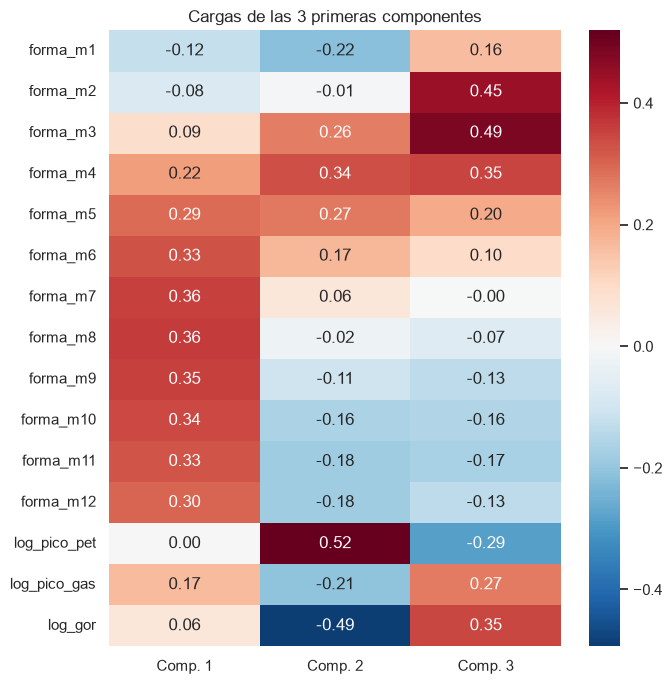

In [4]:
nombres = [f"forma_m{i}" for i in range(1, MESES + 1)] + ["log_pico_pet", "log_pico_gas", "log_gor"]
cargas = pd.DataFrame(svd.components_[:3].T, index=nombres, columns=["Comp. 1", "Comp. 2", "Comp. 3"])
plt.figure(figsize=(7, 7)); sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cargas de las 3 primeras componentes"); plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_cargas_svd.png", dpi=110); plt.show()

La **componente 1** la dominan los meses 4 a 12 de la curva normalizada: separa pozos que **sostienen** su producción de los que **declinan rápido**. La **componente 2** opone el pico de petróleo (+0,52) al GOR (−0,49): separa **petróleo de gas**. La **componente 3** describe el arranque (meses 2–3).

## 2. Elección de k (K-Means)

> **Qué hace esta celda:** prueba K-Means con k de 2 a 10 y calcula cuatro métricas: inercia (método del codo), silhouette, Davies-Bouldin y Calinski-Harabasz.

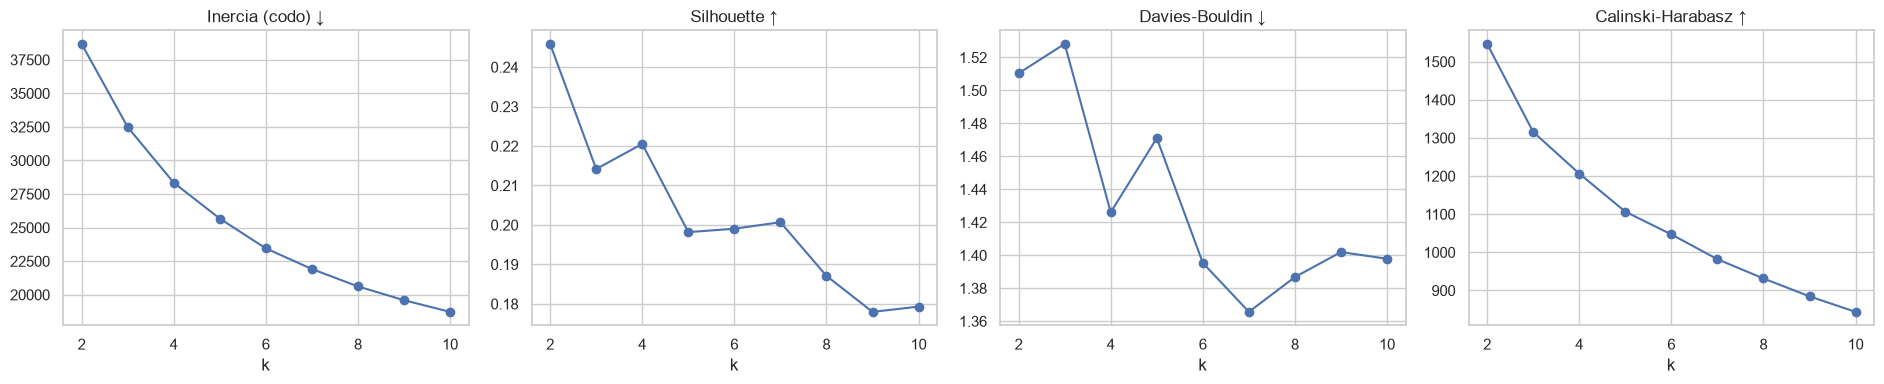

,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,38686.029,0.246,1.510,1546.602
3,32487.421,0.214,1.528,1315.684
4,28346.872,0.221,1.426,1206.570
5,25673.585,0.198,1.471,1106.651
6,23455.858,0.199,1.395,1047.041
7,21917.578,0.201,1.366,981.951
8,20622.621,0.187,1.387,931.400
9,19594.998,0.178,1.402,884.620
10,18726.510,0.179,1.398,843.896


In [5]:
Z = TruncatedSVD(n_components=6, random_state=42).fit_transform(Ms)
res = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=42).fit(Z)
    res.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                "davies_bouldin": davies_bouldin_score(Z, km.labels_), "calinski_harabasz": calinski_harabasz_score(Z, km.labels_)})
res = pd.DataFrame(res).set_index("k")
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
titulos = {"inercia": "Inercia (codo) ↓", "silhouette": "Silhouette ↑", "davies_bouldin": "Davies-Bouldin ↓", "calinski_harabasz": "Calinski-Harabasz ↑"}
for a, col in zip(ax, res.columns): res[col].plot(ax=a, marker="o", title=titulos[col])
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_codo_silhouette.png", dpi=110); plt.show(); res.round(3)

- **Silhouette** (−1 a 1): qué tan cerca está cada pozo de su grupo comparado con el grupo vecino. Mayor es mejor.
- **Davies-Bouldin**: relación entre dispersión interna y separación de los grupos. Menor es mejor.
- **Calinski-Harabasz**: dispersión entre grupos / dispersión interna. Mayor es mejor.

El entrenamiento elige k entre 3 y 8 por silhouette: **k = 4**, que también tiene uno de los menores Davies-Bouldin. Los valores (silhouette ≈ 0,22) indican una estructura **débil**: los grupos son tramos de un continuo.

## 3. DBSCAN
Elegimos `eps` con el gráfico de distancia al k-ésimo vecino (codo).

> **Qué hace esta celda:** grafica la distancia de cada pozo a su 10º vecino más cercano (ayuda a elegir `eps`) y prueba DBSCAN con tres valores, reportando clusters, porcentaje de ruido y silhouette.

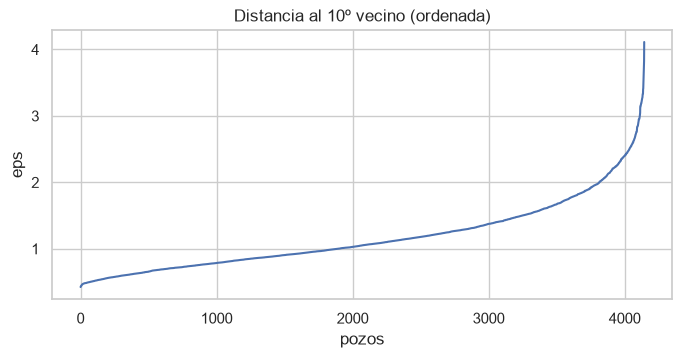

,clusters,% ruido,silhouette (sin ruido)
eps,,,
0.6,3,84.4,0.251
0.9,3,48.0,0.180
1.2,3,23.4,0.304


In [6]:
d = np.sort(NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1])
plt.figure(figsize=(8, 3.5)); plt.plot(d); plt.title("Distancia al 10º vecino (ordenada)"); plt.ylabel("eps"); plt.xlabel("pozos"); plt.show()
filas_db = []
for eps in [0.6, 0.9, 1.2]:
    lab_db = DBSCAN(eps=eps, min_samples=10).fit_predict(Z)
    n_c = len(set(lab_db)) - (-1 in lab_db)
    sil = silhouette_score(Z[lab_db != -1], lab_db[lab_db != -1]) if n_c > 1 else float("nan")
    filas_db.append({"eps": eps, "clusters": n_c, "% ruido": round((lab_db == -1).mean() * 100, 1), "silhouette (sin ruido)": round(sil, 3)})
pd.DataFrame(filas_db).set_index("eps")

DBSCAN marca como **ruido** entre el 23 % y el 84 % de los pozos según `eps`: las curvas forman un **continuo** con densidad desigual. Aunque su silhouette sin ruido puede ser algo mayor, no sirve para asignarle un tipo a *todos* los pozos, que es lo que necesita la API. K-Means agrupa el 100 %, por eso es el elegido.

## 4. Perfiles de los clusters

> **Qué hace esta celda:** carga el clustering final entrenado (`models/clustering.joblib`), asigna el cluster de cada pozo y muestra el perfil de cada grupo.

In [7]:
art = joblib.load(config.DIR_MODELOS / "clustering.joblib")
lab = np.array([art["asignacion"][i] for i in ids])
perfiles = pd.DataFrame(art["perfiles"]).set_index("cluster"); perfiles

,pozos,fluido,pico_pet_mediano_m3,pico_gas_mediano_Mm3,gor_mediano,retencion_mes12,nombre
cluster,,,,,,,
0,1621,Petróleo,3240.7,692.5,174.0,0.295,Petróleo · pico alto · declinación fuerte
1,1300,Petróleo,2130.4,1127.4,441.0,0.545,Petróleo · pico medio · declinación suave
2,529,Petróleo,154.7,463.1,1447.0,0.144,Petróleo · pico bajo · declinación fuerte
3,694,Gas,0.0,4724.2,NaN,0.487,Gas · declinación suave


> **Qué hace esta celda:** grafica la cantidad de pozos por cluster.

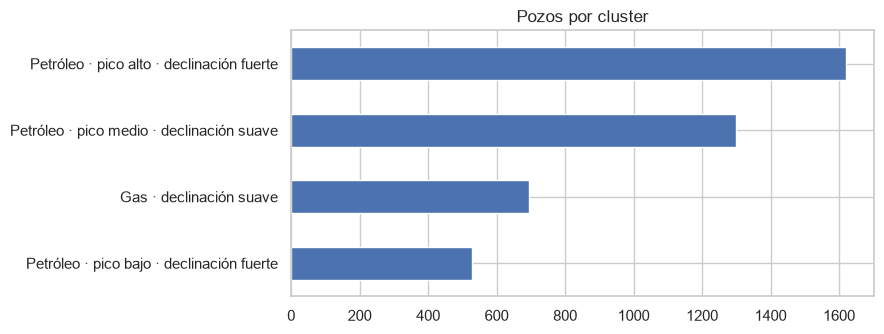

In [8]:
ax = pd.Series(lab).map(perfiles["nombre"]).value_counts().sort_values().plot.barh(color="C0", figsize=(9, 3.5))
ax.set_title("Pozos por cluster"); plt.tight_layout(); plt.show()

> **Qué hace esta celda:** grafica la curva mediana normalizada de cada cluster y los pozos proyectados en las dos primeras componentes SVD, coloreados por cluster.

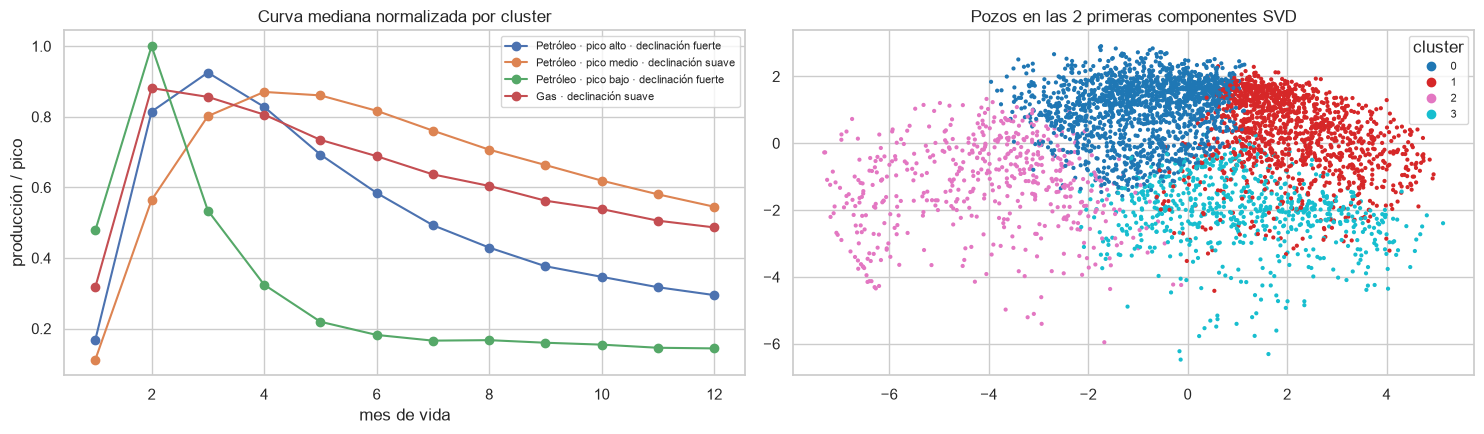

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for k in sorted(set(lab)):
    ax[0].plot(range(1, MESES + 1), np.median(M[lab == k, :MESES], axis=0), marker="o", label=perfiles.loc[k, "nombre"])
ax[0].set_title("Curva mediana normalizada por cluster"); ax[0].set_xlabel("mes de vida"); ax[0].set_ylabel("producción / pico"); ax[0].legend(fontsize=8)
Z2 = TruncatedSVD(2, random_state=42).fit_transform(Ms)
sc = ax[1].scatter(Z2[:, 0], Z2[:, 1], c=lab, s=4, cmap="tab10"); ax[1].set_title("Pozos en las 2 primeras componentes SVD")
ax[1].legend(*sc.legend_elements(), title="cluster", fontsize=8)
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_clusters.png", dpi=110); plt.show()

> **Qué hace esta celda:** compara con boxplots el pico de petróleo, el pico de gas y la retención al mes 12 (producción mes 12 / pico) entre clusters.

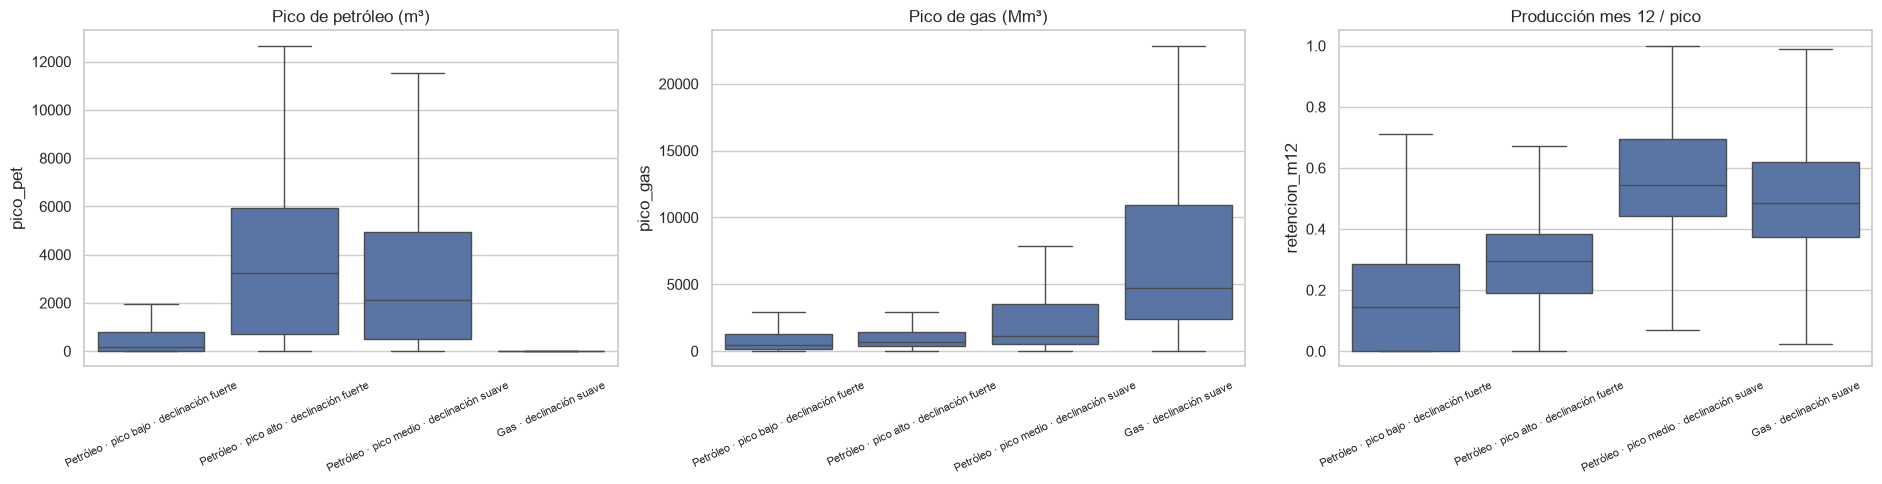

In [10]:
dfc = pd.DataFrame({"cluster": pd.Series(lab).map(perfiles["nombre"]), "pico_pet": np.expm1(M[:, MESES]),
                    "pico_gas": np.expm1(M[:, MESES + 1]), "retencion_m12": M[:, MESES - 1]})
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a, col, t in zip(ax, ["pico_pet", "pico_gas", "retencion_m12"], ["Pico de petróleo (m³)", "Pico de gas (Mm³)", "Producción mes 12 / pico"]):
    sns.boxplot(data=dfc, x="cluster", y=col, ax=a, showfliers=False); a.set_title(t); a.set_xlabel(""); a.tick_params(axis="x", rotation=25, labelsize=8)
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_boxplot_clusters.png", dpi=110); plt.show()

## 5. Validación de los clusters

> **Qué hace esta celda:** grafica el **silhouette de cada pozo** agrupado por cluster: muestra qué tan bien asignado está cada pozo (valores negativos = probablemente estaría mejor en otro grupo).

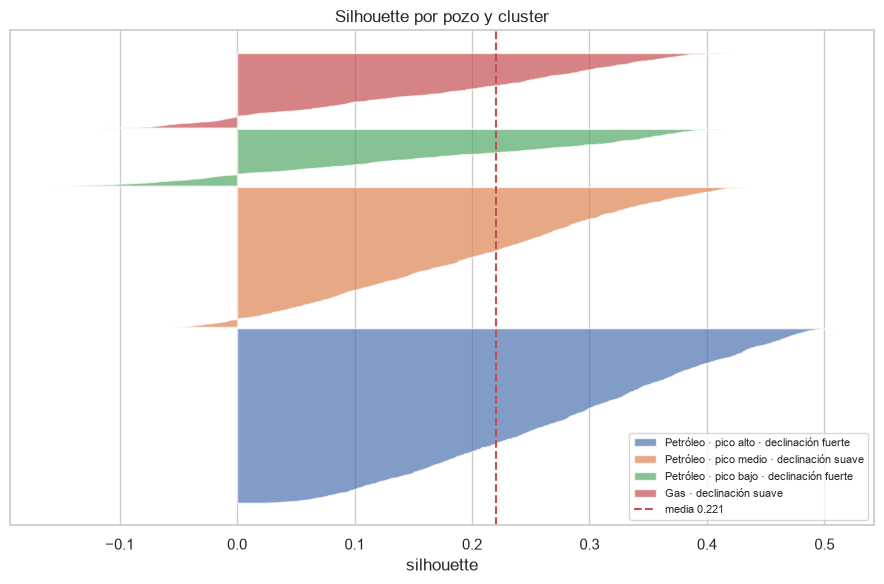

Pozos con silhouette negativo: 7.1%


In [11]:
sil = silhouette_samples(Z, lab)
fig, ax = plt.subplots(figsize=(9, 6)); y0 = 10
for k in sorted(set(lab)):
    v = np.sort(sil[lab == k])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=.7, label=perfiles.loc[k, "nombre"])
    y0 += len(v) + 10
ax.axvline(sil.mean(), color="r", ls="--", label=f"media {sil.mean():.3f}"); ax.set_xlabel("silhouette"); ax.set_yticks([])
ax.set_title("Silhouette por pozo y cluster"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_silhouette_pozos.png", dpi=110); plt.show()
print(f"Pozos con silhouette negativo: {(sil < 0).mean():.1%}")

La mayoría de los pozos tiene silhouette positivo; los negativos están en los bordes entre grupos, consistente con un continuo de comportamientos.

> **Qué hace esta celda:** cruza los clusters con la formación y con el fluido real del pozo en una **tabla de contingencia** (la versión no supervisada de una matriz de confusión), normalizada por fila.

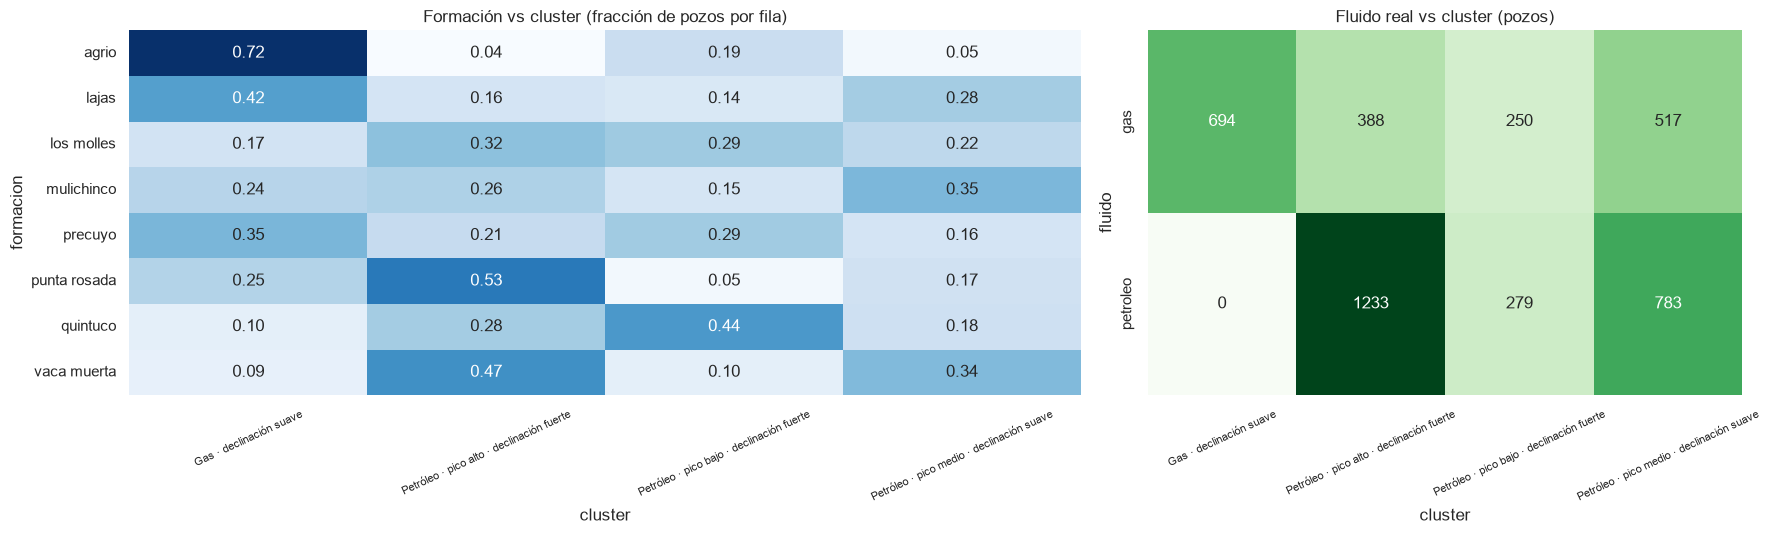

In [12]:
info = pozos.filter(pl.col("idpozo").is_in(ids.tolist())).to_pandas().set_index("idpozo").loc[ids]
info["cluster"] = pd.Series(lab, index=info.index).map(perfiles["nombre"])
fig, ax = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
tf = pd.crosstab(info.formacion, info.cluster, normalize="index").loc[lambda d: info.formacion.value_counts().reindex(d.index) > 30]
sns.heatmap(tf, annot=True, fmt=".2f", cmap="Blues", ax=ax[0], cbar=False); ax[0].set_title("Formación vs cluster (fracción de pozos por fila)")
sns.heatmap(pd.crosstab(info.fluido, info.cluster), annot=True, fmt="d", cmap="Greens", ax=ax[1], cbar=False); ax[1].set_title("Fluido real vs cluster (pozos)")
for a in ax: a.tick_params(axis="x", rotation=25, labelsize=8)
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "04_contingencia.png", dpi=110); plt.show()

- **Fluido:** ningún pozo de petróleo cae en el cluster de gas, pero ese cluster reúne solo 694 de los 1.849 pozos de gas: es el grupo del **gas seco**. Los demás pozos de gas (con condensado o petróleo asociado) se agrupan con los de petróleo según la **forma** de su curva. El clustering separa bien el gas seco, no todo el gas.
- **Formación:** Vaca Muerta se reparte entre los tipos de petróleo (47 % pico alto, 34 % pico medio). Agrio es mayormente gas (72 %); Lajas y Mulichinco se dividen entre gas y petróleo de pico medio, coherente con su mezcla de gas y condensado.

## Conclusiones del clustering
1. **Representación:** describir cada pozo por la forma normalizada de su curva + tamaño del pico + GOR evita los cocientes extremos de la versión 1; con **6 componentes SVD** se conserva el 85 % de la información.
2. **K-Means con k = 4:** tres tipos de pozos de petróleo (pico alto, medio y bajo, con distinta velocidad de declinación) y uno de gas.
3. **Calidad:** silhouette ≈ 0,22 y algunos pozos con silhouette negativo → estructura **débil**, los grupos son tramos de un continuo y no familias aisladas.
4. **DBSCAN** no es adecuado acá: deja como ruido entre el 23 % y el 84 % de los pozos.
5. **Validación externa:** ningún pozo de petróleo cae en el grupo de gas, que reúne al gas seco; los pozos de gas con condensado se agrupan con los de petróleo por la forma de su curva.
6. **Uso:** la API informa el tipo de pozo (existente o predicho) como contexto técnico de cada predicción.

➡️ El notebook **05** explica qué variables mueven las predicciones.